# 2. Logistic regression from scratch

**Goal:** implement binary logistic regression in NumPy ([`src/logistic_regression.py`](../src/logistic_regression.py)), verify it against scikit-learn, and build a tuned baseline income model.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

from src.logistic_regression import LogisticRegressionScratch
from src.features import FeatureBuilder, load_processed, TARGET

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIGURES = "../figures"

## 2.1 Features
The [`FeatureBuilder`](../src/features.py) one-hot encodes the categorical columns, applies `log1p` to the skewed capital gain/loss columns, and standardizes every column. All statistics (categories, means, standard deviations) come from the **training set only**, so no information from the test set leaks into the model.

Standardizing matters for gradient descent: with raw features, `age` (around 40) and a 0/1 dummy would need very different step sizes, and one learning rate cannot suit both.

In [2]:
train, test = load_processed()
y_train, y_test = train[TARGET].to_numpy(), test[TARGET].to_numpy()

fb = FeatureBuilder(include_sensitive=True)
X_train = fb.fit_transform(train)
X_test = fb.transform(test)
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("First features:", list(fb.columns_[:8]))

X_train: (32537, 52)  X_test: (16281, 52)
First features: ['age', 'education-num', 'hours-per-week', 'capital-gain', 'capital-loss', 'workclass=Federal-gov', 'workclass=Local-gov', 'workclass=Never-worked']


## 2.2 Implement and verify
### Training converges
The class minimizes the mean cross-entropy (optionally weighted per observation, which notebook 3 needs) plus an L2 penalty, using mini-batch gradient descent.

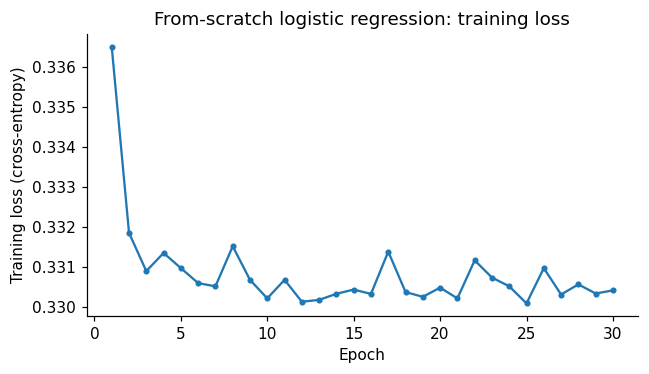

Final training loss: 0.3304


In [3]:
model = LogisticRegressionScratch(learning_rate=0.1, epochs=30, batch_size=128, l2=0.0, random_state=0)
model.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, model.epochs + 1), model.loss_history_, marker="o", ms=3)
ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss (cross-entropy)")
ax.set_title("From-scratch logistic regression: training loss")
plt.tight_layout()
plt.savefig(f"{FIGURES}/training_loss.png", bbox_inches="tight")
plt.show()
print(f"Final training loss: {model.loss_history_[-1]:.4f}")

### Same answer as scikit-learn
scikit-learn's `LogisticRegression` solves the same problem with an exact solver (L-BFGS). Without a penalty, both should find (nearly) the same coefficients.

Test accuracy  scratch: 0.8468   scikit-learn: 0.8474
Identical predictions on 99.05% of test rows; coefficient correlation 0.9904


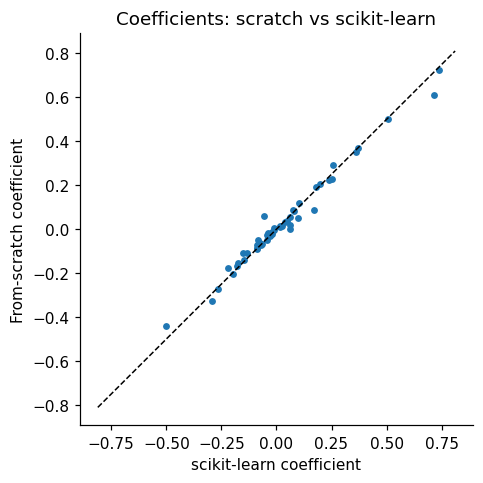

In [4]:
sk = LogisticRegression(penalty=None, max_iter=5000).fit(X_train, y_train)

acc_scratch = accuracy_score(y_test, model.predict(X_test))
acc_sk = accuracy_score(y_test, sk.predict(X_test))
agree = np.mean(model.predict(X_test) == sk.predict(X_test))
corr = np.corrcoef(model.coef_, sk.coef_.ravel())[0, 1]
print(f"Test accuracy  scratch: {acc_scratch:.4f}   scikit-learn: {acc_sk:.4f}")
print(f"Identical predictions on {agree:.2%} of test rows; coefficient correlation {corr:.4f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(sk.coef_.ravel(), model.coef_, s=12)
lim = np.abs(np.r_[sk.coef_.ravel(), model.coef_]).max() * 1.1
ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)
ax.set_xlabel("scikit-learn coefficient")
ax.set_ylabel("From-scratch coefficient")
ax.set_title("Coefficients: scratch vs scikit-learn")
plt.tight_layout()
plt.savefig(f"{FIGURES}/scratch_vs_sklearn.png", bbox_inches="tight")
plt.show()

The from-scratch model matches scikit-learn: test accuracy 84.7% for both, identical predictions for 99% of people, and a coefficient correlation of 0.99. The small differences have two causes:
- gradient descent stops after 30 epochs with a fixed learning rate, so it is very close to, but not exactly at, the optimum;
- every category gets its own dummy column (no reference category), so the coefficients are not unique. For example, only the *difference* between `sex=Male` and `sex=Female` matters, and the two solvers can split it differently while making the same predictions.

## 2.3 Baseline model
### Tune the L2 penalty with cross-validation
Only the training set is used for tuning; the test set is touched once, at the end.

In [5]:
def cv_scores(l2, X, y, n_splits=5, seed=0):
    folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    aucs, losses = [], []
    for tr, va in folds.split(X, y):
        m = LogisticRegressionScratch(learning_rate=0.1, epochs=30, batch_size=128, l2=l2, random_state=0).fit(X[tr], y[tr])
        p = np.clip(m.predict_proba(X[va]), 1e-12, 1 - 1e-12)
        aucs.append(roc_auc_score(y[va], p))
        losses.append(-np.mean(y[va] * np.log(p) + (1 - y[va]) * np.log(1 - p)))
    return np.mean(losses), np.std(losses) / np.sqrt(n_splits), np.mean(aucs)

results = pd.DataFrame([(l2, *cv_scores(l2, X_train, y_train)) for l2 in [0, 1e-4, 1e-3, 1e-2, 1e-1]],
                       columns=["l2", "CV log-loss", "SE", "CV ROC AUC"]).set_index("l2")
results.round(4)

,CV log-loss,SE,CV ROC AUC
l2,,,
0.0000,0.3317,0.0031,0.8996
0.0001,0.3317,0.0031,0.8996
0.0010,0.3317,0.0031,0.8997
0.0100,0.3324,0.0031,0.8995
0.1000,0.3512,0.0026,0.8960


The penalty hardly matters: every value from 0 to 0.01 gives the same cross-validated log-loss within one standard error, and only the strongest penalty (0.1) is clearly worse. With about 32,500 people and only 52 features, the model has little room to overfit. I use the value with the lowest CV log-loss (0.001).

In [6]:
BEST_L2 = results["CV log-loss"].idxmin()
baseline = LogisticRegressionScratch(learning_rate=0.1, epochs=30, batch_size=128, l2=BEST_L2, random_state=0).fit(X_train, y_train)

p_test = baseline.predict_proba(X_test)
pred_test = baseline.predict(X_test)
always_zero = np.zeros_like(y_test)

def summary(y, pred, proba=None):
    return {"accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred),
            "ROC AUC": roc_auc_score(y, proba) if proba is not None else 0.5}

pd.DataFrame({"Always <=50K": summary(y_test, always_zero),
              f"Logistic regression (l2={BEST_L2})": summary(y_test, pred_test, p_test)}).T.round(3)

,accuracy,precision,recall,ROC AUC
Always <=50K,0.764,0.000,0.000,0.500
Logistic regression (l2=0.001),0.847,0.715,0.582,0.898


The model is clearly better than the 76% "always <=50K" baseline: 84.7% accuracy and a ROC AUC of 0.90, so it ranks high and low earners well.

At the default 0.5 threshold, precision is 72% (when it says >50K, it is right about 7 times in 10) and recall is 58% (it finds just over half of the real high earners). The threshold is a business choice: a lower one finds more high earners at the cost of more false alarms.

In [7]:
# Published results drop rows with missing values from the test set, so compare on the same rows
known = ~(test[["workclass", "occupation", "native-country"]] == "Unknown").any(axis=1).to_numpy()
print(f"Test accuracy, all rows ({len(y_test):,}): {accuracy_score(y_test, pred_test):.4f}")
print(f"Test accuracy, rows without missing values ({known.sum():,}): {accuracy_score(y_test[known], pred_test[known]):.4f}")

Test accuracy, all rows (16,281): 0.8466
Test accuracy, rows without missing values (15,060): 0.8414


### How does this compare with published results?
The dataset documentation (`data/raw/adult.names`) lists test accuracies from the original paper (Kohavi, 1996) and later runs, all on the same official train/test split but **with rows that have missing values removed** (15,060 test rows). On those same rows this model reaches 84.1%:

| Model | Test accuracy |
|---|---|
| Nearest neighbour (k = 3) | 79.7% |
| Naive Bayes | 83.9% |
| **This model (logistic regression)** | **84.1%** |
| C4.5 decision tree | 84.5% |
| NBTree (Kohavi, 1996) | 85.9% |

The model is in the same range as the classic decision-tree methods and about 2 points below the best published result, which is reasonable for a linear model. The comparison is not exact: those models were also *trained* without the rows that have missing values. Rows with missing values are easier to predict (they are mostly low earners), which is why accuracy on the full test set is higher (84.7%).

### What drives the prediction?
Because all features are standardized, coefficient sizes are comparable: each one is the change in log-odds of earning >50K for a one-standard-deviation increase in that feature. For a 0/1 dummy, going from 0 to 1 is not one standard deviation but 1/SD of them (about 2 for `sex`), so the effect of being in a category has to be converted (done for sex below).

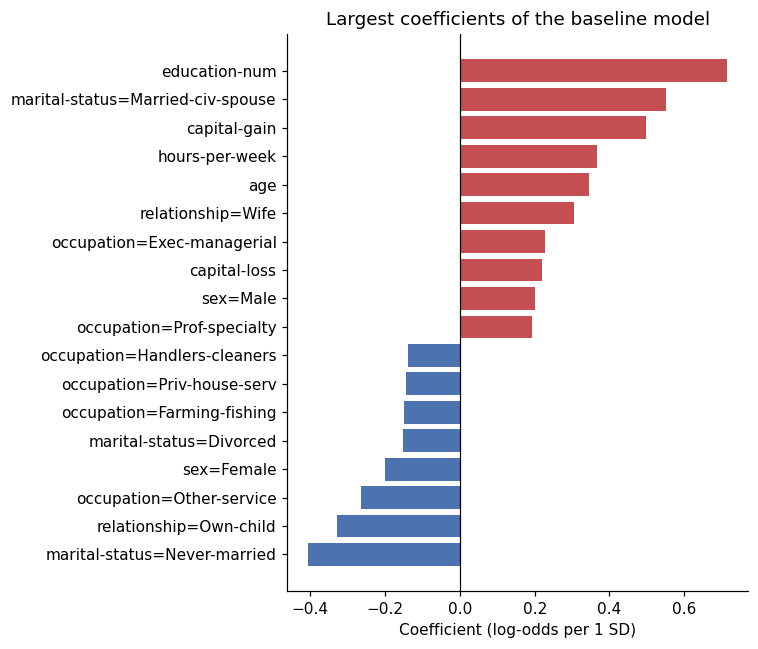

sex=Female                -0.201
race=Other                -0.049
race=Amer-Indian-Eskimo   -0.024
race=Black                -0.004
race=White                 0.015
race=Asian-Pac-Islander    0.015
sex=Male                   0.201
dtype: float64

Male vs female, all else equal: +0.85 log-odds (odds x2.35)


In [8]:
coefs = pd.Series(baseline.coef_, index=fb.columns_).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(10)])

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#C44E52", "#4C72B0"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Coefficient (log-odds per 1 SD)")
ax.set_title("Largest coefficients of the baseline model")
plt.tight_layout()
plt.savefig(f"{FIGURES}/top_coefficients.png", bbox_inches="tight")
plt.show()
print(coefs[[c for c in coefs.index if c.startswith(("sex", "race"))]].round(3))

# A dummy going from 0 to 1 moves 1/SD standardized units, so convert to the effect for one person
sex_effect = coefs["sex=Male"] / fb.std_["sex=Male"] - coefs["sex=Female"] / fb.std_["sex=Female"]
print(f"\nMale vs female, all else equal: {sex_effect:+.2f} log-odds (odds x{np.exp(sex_effect):.2f})")

- The strongest positive drivers are **education**, being **married** (civilian spouse), **capital gains**, **hours worked** and **age**, which matches the exploration in notebook 1.
- Never-married people, people listed as someone's own child (mostly young), and service, cleaning and farming jobs push the prediction down.
- **The model uses sex directly:** with everything else held equal, being male raises the log-odds of earning >50K by about 0.85, i.e. the odds are about 2.3 times as high as for an otherwise identical woman. (The raw coefficients, +0.20 and −0.20, understate this because they are per standard deviation of the dummy.) The race coefficients are small. Notebook 3 measures what this means for the people being scored.
- `relationship=Wife` is positive. This is a *conditional* effect: the model already lowers the score for being female, and among women, being married goes with higher household-reported income.

## Summary

- Implemented logistic regression with mini-batch gradient descent, L2 regularization and sample weights in NumPy. It matches scikit-learn (99% identical predictions).
- Tuned the penalty with stratified 5-fold cross-validation on the training set only. Regularization barely matters at this data size.
- Baseline test results: 84.7% accuracy (vs 76.4% for always predicting <=50K), ROC AUC 0.90, precision 0.72, recall 0.58.
- The model relies on education, marital status, capital gains, hours and age, and it also uses `sex` directly. This is the starting point for the fairness audit.